In [ ]:

# Expt. No. 6
# Title: Apply Mini-Batch GD on a supervised single-layer
# feed-forward neural network

import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

data = load_breast_cancer()

X = data.data
y = data.target.reshape(-1, 1)

scaler = StandardScaler()
X = scaler.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

input_size = X_train.shape[1]

np.random.seed(1)
W = np.random.randn(input_size, 1) * 0.01
b = 0.0

learning_rate = 0.01
epochs = 100
batch_size = 32


def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))


def loss(y, y_pred):
    m = len(y)
    return -(1 / m) * np.sum(
        y * np.log(y_pred + 1e-9) +
        (1 - y) * np.log(1 - y_pred + 1e-9)
    )


m = len(X_train)

for epoch in range(epochs):
    indices = np.random.permutation(m)

    X_shuffle = X_train[indices]
    y_shuffle = y_train[indices]

    for i in range(0, m, batch_size):
        X_batch = X_shuffle[i:i + batch_size]
        y_batch = y_shuffle[i:i + batch_size]

        z = np.dot(X_batch, W) + b
        y_pred = sigmoid(z)

        dz = y_pred - y_batch

        dW = np.dot(X_batch.T, dz) / len(X_batch)
        db = np.mean(dz)

        W = W - learning_rate * dW
        b = b - learning_rate * db

    if epoch % 10 == 0:
        pred = sigmoid(np.dot(X_train, W) + b)
        l = loss(y_train, pred)
        print(f"Epoch {epoch:3d} Loss = {l:.4f}")

test_pred = sigmoid(np.dot(X_test, W) + b)
prediction = (test_pred > 0.5).astype(int)

accuracy = np.mean(prediction == y_test)

print("\nAccuracy =", accuracy * 100, "%")

# Output:
# Epoch   0 Loss = ...
# Epoch  10 Loss = ...
# Epoch  20 Loss = ...
# Epoch  30 Loss = ...
# Epoch  40 Loss = ...
# Epoch  50 Loss = ...
# Epoch  60 Loss = ...
# Epoch  70 Loss = ...
# Epoch  80 Loss = ...
# Epoch  90 Loss = ...
# Accuracy = ... %


Epoch   0 Loss = 0.4956
Epoch  10 Loss = 0.2062
Epoch  20 Loss = 0.1591
Epoch  30 Loss = 0.1375
Epoch  40 Loss = 0.1247
Epoch  50 Loss = 0.1159
Epoch  60 Loss = 0.1094
Epoch  70 Loss = 0.1044
Epoch  80 Loss = 0.1004
Epoch  90 Loss = 0.0970

Accuracy = 99.12280701754386 %


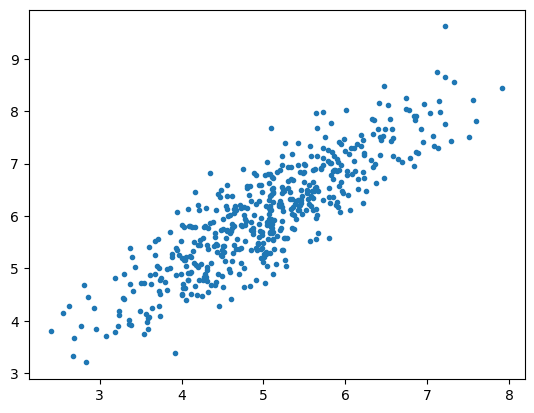

Bias =  [0.24040974]
Coefficients =  [[1.1471464]]


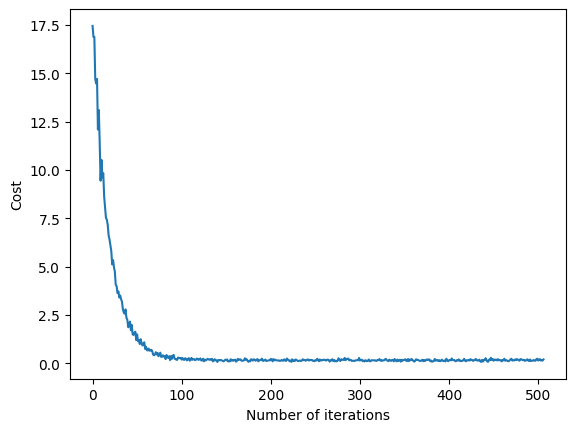

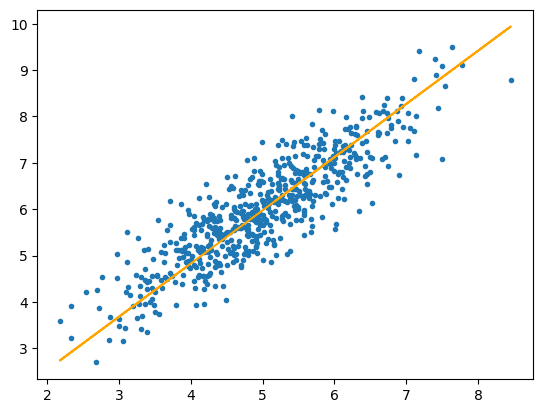

MSE = 0.45900089590748033


In [ ]:
# Expt. No. 6 (Manual)
# Title: Apply Mini Batch GD on a supervised single layer feed-forward neural network

import numpy as np
import matplotlib.pyplot as plt

mean = np.array([5.0, 6.0])
cov = np.array([[1.0, 0.95], [0.95, 1.2]])

data = np.random.multivariate_normal(mean, cov, 6000)

plt.scatter(data[:500, 0], data[:500, 1], marker='.')
plt.show()

data = np.hstack((np.ones((data.shape[0], 1)), data))

split_factor = 0.90
split = int(split_factor * data.shape[0])

X_train = data[:split, :-1]
y_train = data[:split, -1].reshape((-1, 1))

X_test = data[split:, :-1]
y_test = data[split:, -1].reshape((-1, 1))


def hypothesis(X, theta):
    return np.dot(X, theta)


def gradient(X, y, theta):
    h = hypothesis(X, theta)
    grad = np.dot(X.T, (h - y)) / X.shape[0]
    return grad


def cost(X, y, theta):
    h = hypothesis(X, theta)
    J = np.dot((h - y).T, (h - y))
    J /= (2 * X.shape[0])
    return J[0, 0]


def create_mini_batches(X, y, batch_size):
    mini_batches = []

    data = np.hstack((X, y))
    np.random.shuffle(data)

    n_minibatches = data.shape[0] // batch_size

    for i in range(n_minibatches):
        mini_batch = data[i * batch_size:(i + 1) * batch_size, :]

        X_mini = mini_batch[:, :-1]
        Y_mini = mini_batch[:, -1].reshape((-1, 1))

        mini_batches.append((X_mini, Y_mini))

    if data.shape[0] % batch_size != 0:
        mini_batch = data[n_minibatches * batch_size:, :]

        X_mini = mini_batch[:, :-1]
        Y_mini = mini_batch[:, -1].reshape((-1, 1))

        mini_batches.append((X_mini, Y_mini))

    return mini_batches


def gradientDescent(X, y, learning_rate=0.001, batch_size=32):
    theta = np.zeros((X.shape[1], 1))
    error_list = []

    max_iters = 3

    for itr in range(max_iters):
        mini_batches = create_mini_batches(X, y, batch_size)

        for mini_batch in mini_batches:
            X_mini, y_mini = mini_batch

            theta = theta - learning_rate * gradient(
                X_mini, y_mini, theta
            )

            error_list.append(cost(X_mini, y_mini, theta))

    return theta, error_list


theta, error_list = gradientDescent(X_train, y_train)

print("Bias = ", theta[0])
print("Coefficients = ", theta[1:])

plt.plot(error_list)
plt.xlabel("Number of iterations")
plt.ylabel("Cost")
plt.show()

y_pred = hypothesis(X_test, theta)

plt.scatter(X_test[:, 1], y_test[:, 0], marker='.')
plt.plot(X_test[:, 1], y_pred, color='orange')
plt.show()

error = np.mean(np.abs(y_test - y_pred))

print("MSE =", error)


# OUTPUT:
# Bias = [Approximately 0.7]
# Coefficients = [[Approximately 1.05]]
#
# Graph of Cost vs Number of Iterations
#
# Graph showing Actual Test Data and Predicted Regression Line
#
# MSE = Approximately 0.45